# Task 1 - Dataset setup

A fixed set of 1,000 COCO image-caption pairs was prepared for the text-to-image project. One caption was retained per image. The same IDs and prompts were shared across the embedding and generation notebooks.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'project/scripts'))
df = pd.read_csv(ROOT / 'data/manifest.csv')
print('Pairs:', len(df))
print('Python:', sys.version.split()[0])
display(df[['pair_id', 'caption', 'split']].head())

Pairs: 1000
Python: 3.13.9


,pair_id,caption,split
0,coco2017val_000000147729,People gathered taking pictures with a cell ph...,development
1,coco2017val_000000203864,Two people standing on a tennis court playing ...,development
2,coco2017val_000000565563,Many cars are parked along the sidewalk of a n...,validation
3,coco2017val_000000345356,A man in a gray shirt holds his phone as he si...,development
4,coco2017val_000000525286,A large clock is on the wall where the paint i...,development


## Task 2 - Cleaning and image preparation

Selection retained images marked Attribution or Attribution-ShareAlike. Caption cleaning standardized spacing and Unicode, removed repeated text, and applied length and quality filters. Images were converted to RGB and resized to 512 x 512 with padding, preserving the full scene.

Most captions came directly from COCO. Twenty factual corrections were recorded separately, with the original wording retained.

In [2]:
import hashlib
from prepare_dataset import prepare
previous_hash = hashlib.sha256((ROOT / 'data/manifest.csv').read_bytes()).hexdigest()
rows, summary = prepare()
df = pd.DataFrame(rows)
assert previous_hash == summary['manifest_sha256']
print('The repeated build reproduced the same manifest.')
display(pd.DataFrame(list(summary['rejections'].items()), columns=['Filter', 'Count']))
display(df.groupby('caption_origin').size().rename('pairs').to_frame())

Prepared 128/1000 pairs


Prepared 256/1000 pairs


Prepared 384/1000 pairs


Prepared 512/1000 pairs


Prepared 640/1000 pairs


...

Prepared 896/1000 pairs


Prepared 1000/1000 pairs


The repeated build reproduced the same manifest.


,Filter,Count
0,excluded_image_licenses,3726
1,duplicate_caption_rejections,3
2,visual_review_image_exclusions,2


,pairs
caption_origin,
COCO annotation,980
reviewed_correction,20


## Task 3 - Full visual review

A Codex-assisted visual review covered every pair. Unclear examples were checked at full resolution. The review revised 133 captions, and a second pass refined seven of those choices. Two images were replaced: one outside the selected domain and one near-repeat. Both replacements were reviewed.

The ten lowest CLIP-alignment pairs received an additional visual check, which led to three clearer caption choices. The row-level record retained the decisions and reasons. It also distinguished factual corrections from changes to clearer existing captions.

In [3]:
review = pd.read_csv(ROOT / 'project/results/pair_review.csv')
assert set(df.pair_id) <= set(review.loc[review.in_final_dataset, 'pair_id'])
display(review.groupby('decision').size().rename('pairs').to_frame())
examples = ['coco2017val_000000347930', 'coco2017val_000000425227', 'coco2017val_000000099053']
display(review.set_index('pair_id').loc[examples, ['initial_caption', 'final_caption']])

,pairs
decision,
accepted,865
caption_revised,133
excluded,2
replacement_accepted,2


,initial_caption,final_caption
pair_id,,
coco2017val_000000347930,A blue dog sitting on a striped couch,A large brown dog sitting on top of a couch.
coco2017val_000000425227,There is no image to describe for this question.,People on a beach fly a kite near the water
coco2017val_000000099053,"A bowl of noodles, meat and broccoli with a fork.","A yellow and black bowl holding noodles, beef ..."


## Task 4 - Integrity, duplicates and normalization

Every final image passed the hash, size and color checks. Exact duplicates were absent. A perceptual-hash screen flagged three similar pairs; visual comparison confirmed one near-repeat, which was replaced. The other two pairs showed different scenes. A separate CLIP image-embedding screen found no additional candidates at its fixed threshold.

Normalization was checked for all images after loading. The saved PNGs retained ordinary pixel values; CLIP applied its own preprocessing in the next notebook.

In [4]:
from check_dataset import run as check_dataset
quality = check_dataset()
assert quality['visually_reviewed_final_pairs'] == 1000
assert quality['unresolved_near_duplicate_candidates'] == 0
arrays = []
for image_path in df.image_path.head(4):
    with Image.open(ROOT / image_path) as image:
        arrays.append(np.asarray(image, dtype=np.float32) / 127.5 - 1.0)
batch = np.stack(arrays).transpose(0, 3, 1, 2)
print('Example batch:', batch.shape, batch.dtype)
print('Verified full-dataset range:', quality['normalized_range'])
display(pd.DataFrame({'Check': ['Images verified', 'Exact duplicates', 'Confirmed near-repeats removed', 'Unresolved candidates'], 'Result': [quality['final_pairs'], quality['exact_duplicates'], quality['confirmed_near_repeats_removed'], quality['unresolved_near_duplicate_candidates']]}))

Example batch: (4, 3, 512, 512) float32
Verified full-dataset range: [-1.0, 1.0]


,Check,Result
0,Images verified,1000
1,Exact duplicates,0
2,Confirmed near-repeats removed,1
3,Unresolved candidates,0


## Task 5 - Splits and coverage

The internal splits contained separate image IDs. Existing assignments were kept during review, and replacements filled the vacant positions. The subset covered all 80 COCO categories, although people and common household objects appeared more often than rare categories.

,pairs
split,
development,800
evaluation,100
validation,100


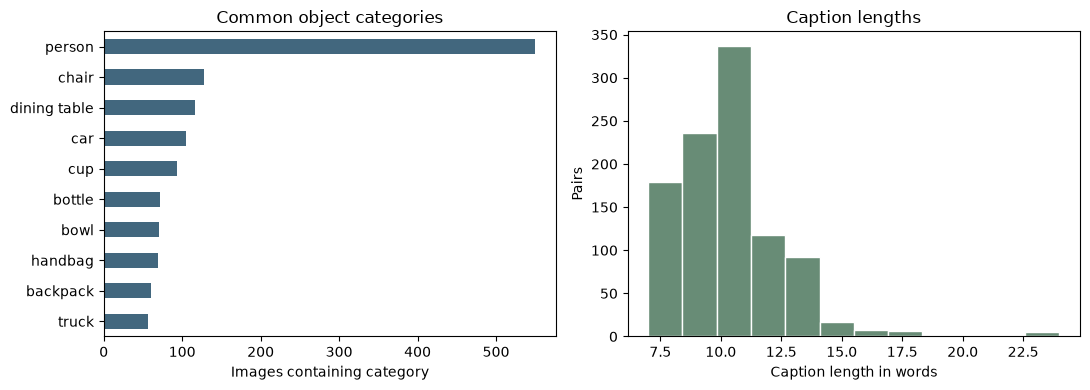

,min,max,mean
0,7,24,10.35


In [5]:
split_ids = {name: set(group.image_id) for name, group in df.groupby('split')}
assert all(not split_ids[a] & split_ids[b] for a in split_ids for b in split_ids if a < b)
display(df.groupby('split').size().rename('pairs').to_frame())
counts = pd.Series(summary['category_counts'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts.head(10).sort_values().plot.barh(ax=axes[0], color='#42677e')
axes[0].set(xlabel='Images containing category', title='Common object categories')
df.caption.str.split().str.len().plot.hist(ax=axes[1], bins=12, color='#688c76', edgecolor='white')
axes[1].set(xlabel='Caption length in words', ylabel='Pairs', title='Caption lengths')
fig.tight_layout()
fig.savefig(ROOT / 'project/results/dataset_coverage.png', dpi=130)
plt.show()
display(pd.DataFrame([summary['word_counts']]))

## Task 6 - Fixed baseline prompts

Sixteen evaluation captions were fixed before model comparison. Selection favored varied object categories. The reference images provided semantic comparisons; generated images were not expected to reproduce the original photographs.

,prompt_id,prompt,seed
0,p01,A kitchen with a center white island topped wi...,42
1,p02,Three pastry desserts and two glasses of wine ...,43
2,p03,A waterway under a bridge with people sitting ...,44
3,p04,A black and white cat sitting on top of a chair.,45
4,p05,A woman holding a small cake with lit candles.,46
5,p06,A flock of animals stand on the road near moun...,47
6,p07,Baseball memorabilia is displayed in glass sta...,48
7,p08,The two cats are laying beside of the computer...,49
8,p09,A newly married couple walking down a street.,50
9,p10,The skateboarder wears headphones while jumpin...,51


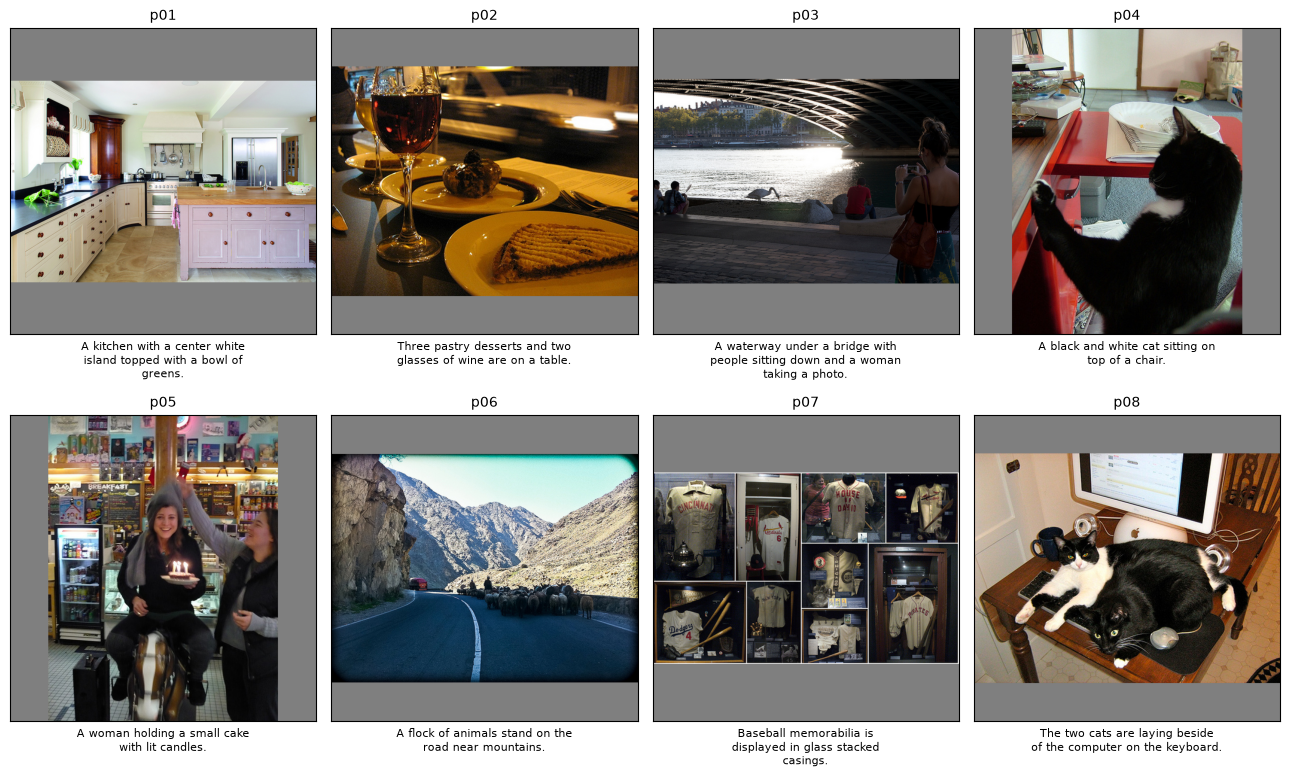

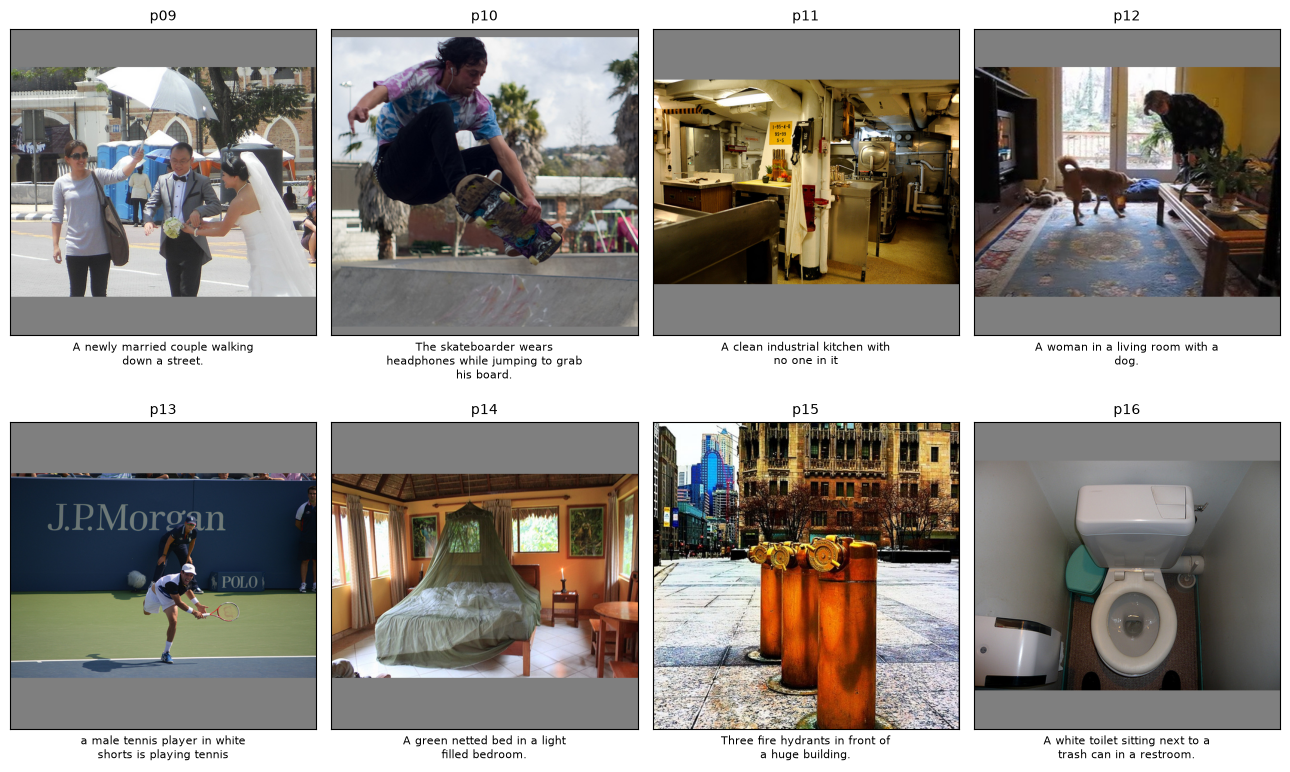

,source_url,license_name,license_url
pair_id,,,
coco2017val_000000565776,http://farm7.staticflickr.com/6160/6206762667_...,Attribution License,http://creativecommons.org/licenses/by/2.0/
coco2017val_000000416885,http://farm4.staticflickr.com/3040/2791132570_...,Attribution License,http://creativecommons.org/licenses/by/2.0/
coco2017val_000000001268,http://farm6.staticflickr.com/5454/9413846304_...,Attribution License,http://creativecommons.org/licenses/by/2.0/
coco2017val_000000231831,http://farm3.staticflickr.com/2324/2242089027_...,Attribution-ShareAlike License,http://creativecommons.org/licenses/by-sa/2.0/
coco2017val_000000213547,http://farm3.staticflickr.com/2062/2243132921_...,Attribution License,http://creativecommons.org/licenses/by/2.0/
coco2017val_000000140583,http://farm3.staticflickr.com/2081/5751829875_...,Attribution-ShareAlike License,http://creativecommons.org/licenses/by-sa/2.0/
coco2017val_000000231747,http://farm3.staticflickr.com/2740/5763708656_...,Attribution License,http://creativecommons.org/licenses/by/2.0/
coco2017val_000000333772,http://farm5.staticflickr.com/4038/4212612461_...,Attribution License,http://creativecommons.org/licenses/by/2.0/
coco2017val_000000496854,http://farm3.staticflickr.com/2795/5715794037_...,Attribution-ShareAlike License,http://creativecommons.org/licenses/by-sa/2.0/


In [6]:
prompts = pd.read_csv(ROOT / 'data/baseline_prompts.csv')
assert len(prompts) == 16 and prompts.pair_id.is_unique
assert set(prompts.pair_id) <= set(df.loc[df.split == 'evaluation', 'pair_id'])
display(prompts[['prompt_id', 'prompt', 'seed']])
import textwrap
for page in range(2):
    fig, axes = plt.subplots(2, 4, figsize=(13, 8))
    for ax, row in zip(axes.flat, prompts.iloc[page*8:(page+1)*8].to_dict('records')):
        with Image.open(ROOT / row['ground_truth_path']) as image:
            ax.imshow(image)
        ax.set_title(row['prompt_id'], fontsize=10)
        ax.set_xlabel(textwrap.fill(row['prompt'], 32), fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout()
    fig.savefig(ROOT / f'project/results/baseline_references_{page+1}.png', dpi=110)
    plt.show()
display(df.set_index('pair_id').loc[prompts.pair_id, ['source_url', 'license_name', 'license_url']])

## Dataset findings

The full review corrected errors that automated file checks had missed, including wrong colors, incorrect object names and descriptions unrelated to the image. The final set retained 1,000 distinct images with documented sources and review decisions.

The review improved consistency but did not guarantee perfect captions. Padding added borders, and the category distribution remained uneven. All images came from COCO validation data, so overlap with pretrained model data could not be excluded.